Author: Enikő Gergely <br>
Date: October 2026
    
# Christian Yelich – Posture Analysis with automated data collection

This notebook analyzes the relationship between Christian Yelich's batting posture during his batting stance and his offensive performance from 2018 to 2026. Using video frames from Baseball Savant, I track his body posture by measuring the Back-Gluteal angle and compare it over time with his batting statistics, mainly OBP.

The preprocessing notebooks include automated image processing, finding player silhouette and angle measurements:
- 01_Collect Savant videos and frames
- 02_Add Back_Gluteal line

This notebook analyzes the output of the automated data collection process and includes outlier removal, average angle and OBP comparison, moving averages of the angles to identify posture trends across seasons. 

The goal is to automate my previous  [study](https://github.com/enikogergely26/YelichPostureAnalysis/blob/main/Christian%20Yelich%20Posture%20Analysis%20-%20EnikoGergely.pdf) and see if the automated process gives the same results that I got with the manual data collection. If results are the same, the automated process can be used to analyze other players and analyze further the relationship between the Back-Gluteal angle and the batting performance. This notebook also extends the analysis of Christian Yelich from 2018-2023 August to 2018-2026.

# Import packages

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# pybaseball:
import pybaseballstats.statcast_single_player as ssp

# read images
import cv2
import matplotlib.pyplot as plt

# silouette
from pathlib import Path
from ultralytics import YOLO
from matplotlib.patches import Rectangle

# Load Data

#### Automated Data Collection Process: 
I download videos from Baseball Savant using the BaseballCV python package. Then I extract frames from the videos and crop the hitter from the frame. I then manually review all the frames to ensure they are correct.
I run a separate notebook to generate silhouette of the hitter, draw the Back-Gluteal line, and calculate its angle. All measurements and related information are saved to Excel files organized by year. 

#### Load Data
Here, I load the yearly Excel files and concatenate them into a single DataFrame for further analysis.


In [2]:
# load angle data from automated process output
df_2019 = pd.read_excel('Yelich_2019.xlsx')
df_2018 = pd.read_excel('Yelich_2018.xlsx')
df_2020 = pd.read_excel('Yelich_2020.xlsx')
df_2021 = pd.read_excel('Yelich_2021.xlsx')
df_2022 = pd.read_excel('Yelich_2022.xlsx')
df_2023Apr = pd.read_excel('Yelich_2023Apr.xlsx')
df_2023MayAug = pd.read_excel('Yelich_2023MayAug.xlsx')
df_2023 = pd.read_excel('Yelich_2023.xlsx')
df_2024 = pd.read_excel('Yelich_2024.xlsx')
df_2025 = pd.read_excel('Yelich_2025.xlsx')
df_2026 = pd.read_excel('Yelich_2026.xlsx')

# concatenate datasets:
df =pd.concat([df_2018, df_2019, df_2020, df_2021, 
               df_2022, 
               #df_2023Apr, df_2023MayAug, 
               df_2023,
               df_2024, 
               df_2025, df_2026])

# Add calculated columns

In [3]:
# Add Year and Month
df['Date'] = pd.to_datetime(df['Date'])
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month


In [4]:
# sample of data
df.head()

,Unnamed: 0,file_name,angle,Date,Year,Month
0,0,cropped_image_529467_3086fe1e-e804-4d93-bdda-8...,97.721826,2018-04-02,2018,4
1,1,cropped_image_529727_95f68b67-46e3-4e2f-b690-9...,108.434949,2018-04-22,2018,4
2,2,cropped_image_529908_c4b67798-ecc4-40d0-9567-2...,97.352379,2018-05-05,2018,5
3,3,cropped_image_529936_c96e2d1d-49b1-4479-9aac-e...,101.309932,2018-05-08,2018,5
4,4,cropped_image_529951_a4bfa5ba-41b3-4716-9959-3...,95.440332,2018-05-09,2018,5


# Remove Outliers
Since some images have imperfect silhouette due to low image quality, I remove outliers by year to improve the data quality.

In [5]:
def remove_outliers(group):
    Q1 = group['angle'].quantile(0.25)
    Q3 = group['angle'].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    return group[
        (group['angle'] >= lower) &
        (group['angle'] <= upper)
    ]


print("Before Outlier Removal: ", len(df))

df_clean = (
    df.groupby('Year', group_keys=False)
      .apply(remove_outliers)
      .reset_index(drop=True)
)

print("After Outlier Removal: ", len(df_clean))
print("Number of items removed: ", len(df) - len (df_clean))

Before Outlier Removal:  477
After Outlier Removal:  449
Number of items removed:  28


C:\Users\eniko\AppData\Local\Temp\ipykernel_1160\2741331505.py:19: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(remove_outliers)


# Get Batting results:

In this section I use the pybaseballstats package to get batting statistics for the selected hitter.

In [6]:
# Christian Yelich's Player id: 
player_id = 592885

In [7]:
# create empty dataframe
player_stats = pd.DataFrame()

# run through years and load batting stats
for season in range(2018, 2027):
    data = ssp.single_player_season_stats(
        player_id=player_id,
        season= season,
        player_type="batter",
    ).to_pandas()

    summary = data[["player_id","player_name", "pa", "ba", "slg", "woba", "xwoba", "obp"]]
    summary['year'] = season

    player_stats = pd.concat([player_stats, summary], ignore_index=True)

# calculate OPS:
player_stats['ops'] = player_stats['obp'] + player_stats['slg']

# see table:
player_stats

C:\Users\eniko\AppData\Local\Temp\ipykernel_1160\2576440887.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  summary['year'] = season
C:\Users\eniko\AppData\Local\Temp\ipykernel_1160\2576440887.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  summary['year'] = season
C:\Users\eniko\AppData\Local\Temp\ipykernel_1160\2576440887.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in t

,player_id,player_name,pa,ba,slg,woba,xwoba,obp,year,ops
0,592885,"Yelich, Christian",651,0.326,0.598,0.422,0.412,0.402,2018,1.000
1,592885,"Yelich, Christian",579,0.330,0.672,0.442,0.426,0.430,2019,1.102
2,592885,"Yelich, Christian",247,0.205,0.430,0.343,0.374,0.356,2020,0.786
3,592885,"Yelich, Christian",475,0.248,0.373,0.325,0.331,0.362,2021,0.735
4,592885,"Yelich, Christian",671,0.252,0.383,0.328,0.340,0.355,2022,0.738
5,592885,"Yelich, Christian",632,0.278,0.447,0.353,0.356,0.370,2023,0.817
6,592885,"Yelich, Christian",315,0.315,0.504,0.391,0.373,0.406,2024,0.910
7,592885,"Yelich, Christian",644,0.264,0.452,0.343,0.330,0.343,2025,0.795
8,592885,"Yelich, Christian",500,0.235,0.378,0.305,0.308,0.315,2026,0.693


# Calculate yearly averages and merge with batting stats

First, I calculate the yearly average angles, and then merge the results with the batting stats table.

In [32]:
# calculate yearly average angles:
average_angle = df_clean.groupby(['Year'])[['angle']].mean().reset_index()

# merge yearly angle averages and batting stats into one df
df_main = average_angle.merge(
    player_stats[["year", "ops", "obp", 'slg', 'woba']],
    left_on="Year",
    right_on="year",
    how="right"
)

df_main

,Year,angle,year,ops,obp,slg,woba
0,2018,98.719940,2018,1.000,0.402,0.598,0.422
1,2019,97.019905,2019,1.102,0.430,0.672,0.442
2,2020,99.743231,2020,0.786,0.356,0.430,0.343
3,2021,98.478170,2021,0.735,0.362,0.373,0.325
4,2022,100.107920,2022,0.738,0.355,0.383,0.328
5,2023,99.305855,2023,0.817,0.370,0.447,0.353
6,2024,98.493440,2024,0.910,0.406,0.504,0.391
7,2025,98.845768,2025,0.795,0.343,0.452,0.343
8,2026,95.693118,2026,0.693,0.315,0.378,0.305


# Analyze data

### Correlation of angle and batting stats
Correlation is quite weak at this point. Let's check the numbers visually.

In [35]:
# correlation
df_main[['angle', 'ops', 'obp', 'slg', 'woba']].corr()[['angle']]

,angle
angle,1.000000
ops,-0.136489
obp,0.055792
slg,-0.197723
woba,-0.071916


### Visualization
I plot the angles on the y-axis inverted: values decrease from bottom to top for easier comparison.

#### Angle vs OBP

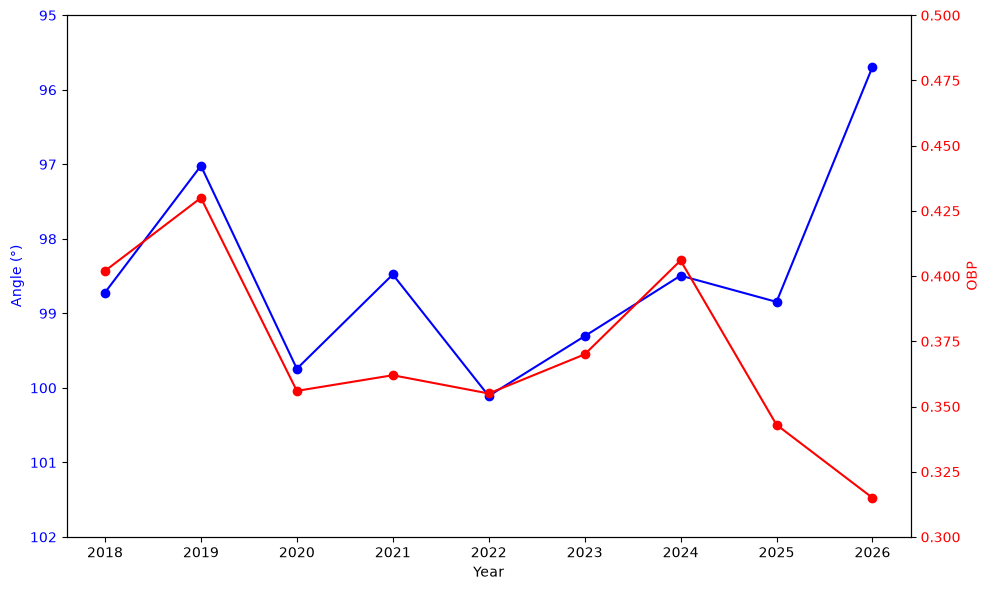

In [31]:
fig, ax1 = plt.subplots(figsize=(10, 6))

# Angle plot
ax1.plot(
    df_main['year'],
    df_main['angle'],
    marker='o',
    color='blue',
    label='Angle'
)
ax1.set_xlabel('Year')
ax1.set_ylabel('Angle (°)', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# OBP plot
ax2 = ax1.twinx()
ax2.plot(
    df_main['year'],
    df_main['obp'],
    marker='o',
    color='red',
    label='OBP'
)
ax2.set_ylabel('OBP', color='red')
ax2.tick_params(axis='y', labelcolor='red')

# set axis manaully:
ax1.set_ylim(102,95)      # Angle axis
ax2.set_ylim(0.30, 0.50)    # OBP axis


plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


There seems to be a strong correlation between 2018 and 2024, followed by a relationship in the opposite direction from 2024 to 2026.


Correlation between 2018 and 2024 between angle and OBP is -0.855, which is very close to the observed correlation in my previous study where data was manually collected.

In [40]:
df_main[df_main['year'] <=2024][['angle', 'ops', 'obp', 'slg', 'woba']].corr()[['angle']]

,angle
angle,1.000000
ops,-0.783635
obp,-0.855379
slg,-0.754063
woba,-0.748921


Correlation between 2024 and 2026 is much lower for angle vs obp, and opposite direction: 0.664. While OPS stayed the same.

In [41]:
df_main[df_main['year'] >=2024][['angle', 'ops', 'obp', 'slg', 'woba']].corr()

,angle,ops,obp,slg,woba
angle,1.000000,0.789791,0.664280,0.865181,0.769469
ops,0.789791,1.000000,0.983131,0.990896,0.999473
obp,0.664280,0.983131,1.000000,0.949556,0.988549
slg,0.865181,0.990896,0.949556,1.000000,0.986004
woba,0.769469,0.999473,0.988549,0.986004,1.000000


#### Angle vs OPS:

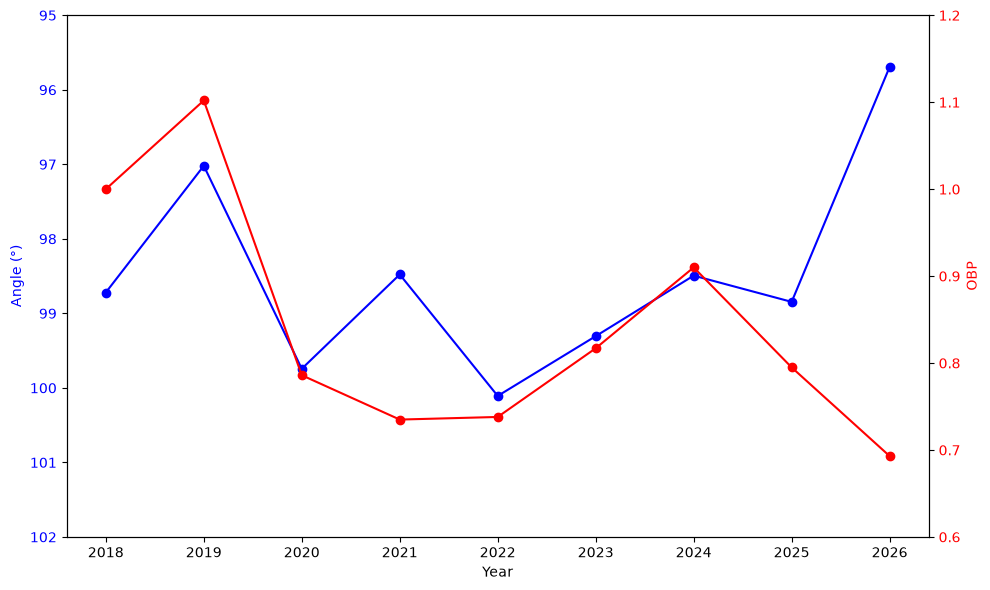

In [42]:
fig, ax1 = plt.subplots(figsize=(10, 6))

# Angle plot
ax1.plot(
    df_main['year'],
    df_main['angle'],
    marker='o',
    color='blue',
    label='Angle'
)
ax1.set_xlabel('Year')
ax1.set_ylabel('Angle (°)', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# OBP plot
ax2 = ax1.twinx()
ax2.plot(
    df_main['year'],
    df_main['ops'],
    marker='o',
    color='red',
    label='OPS'
)
ax2.set_ylabel('OPS', color='red')
ax2.tick_params(axis='y', labelcolor='red')

# set axis manaully:
ax1.set_ylim(102,95)      # Angle axis
ax2.set_ylim(0.6, 1.2)    # OPS axis

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 5-measure moving average
Here, I calculate a 5 measure moving average for each year separately just to smooth out large fluctuations in the angle measurements. Then I plot the moving average for all years on a single chart to compare the trends. 

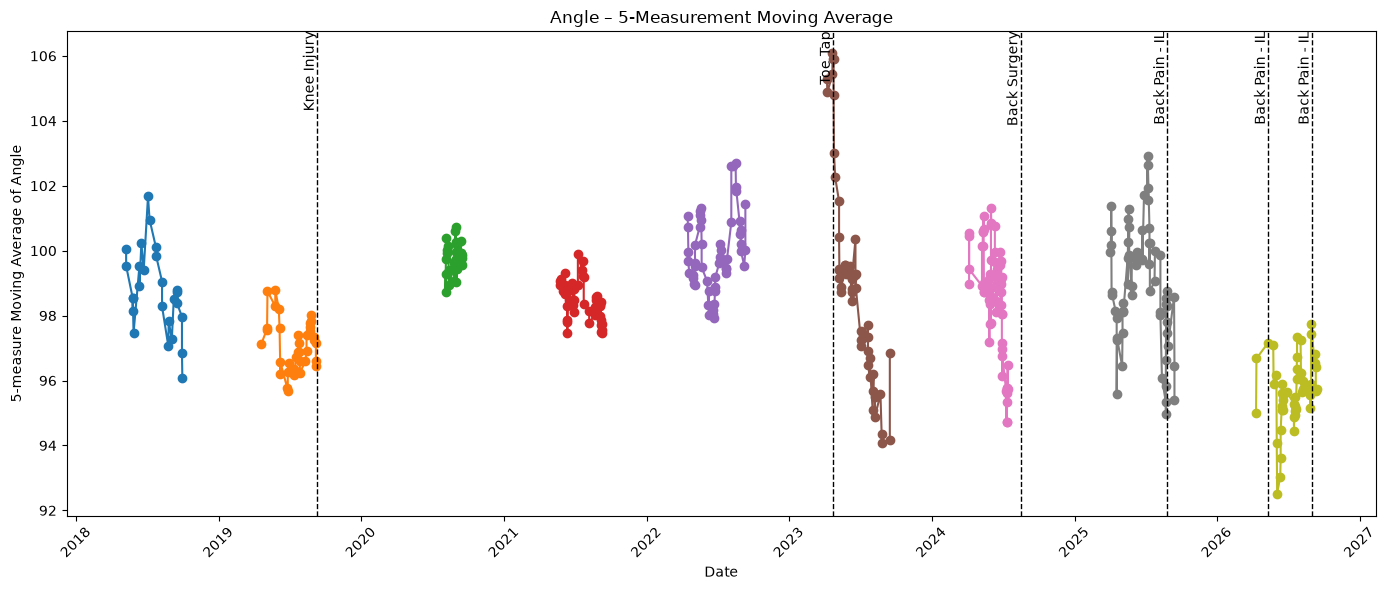

In [48]:
# create a copy of the original cleaned (after outlier removal) table.
df_chart = df_clean.copy()

# sort by date:
df_chart = df_chart.sort_values('Date')

# 5-measure moving average for each year separately:
df_chart['angle_ma5'] = (
    df_chart.groupby('Year')['angle']
      .transform(lambda x: x.rolling(5).mean())
)



### Plot ###
fig, ax = plt.subplots(figsize=(14, 6))

# Create separate plot for every year so they are not connected
for year, group in df_chart.groupby(df_chart['Date'].dt.year):
    ax.plot(
        group['Date'],
        group['angle_ma5'],
        marker='o',
        label=str(year)
    )

ax.set_xlabel('Date')
ax.set_ylabel('5-measure Moving Average of Angle')
ax.set_title('Angle – 5-Measurement Moving Average')


# Add some dates that represents important events in Christian Yelich's career: 

#  Knee Injury
ax.axvline(
    pd.Timestamp('2019-09-10'),
    color='black',
    linestyle='--',
    linewidth=1
)

ax.text(
    pd.Timestamp('2019-09-10'),
    ax.get_ylim()[1],
    'Knee Injury',
    rotation=90,
    va='top',
    ha='right'
)


# Back Surgery
ax.axvline(
    pd.Timestamp('2024-08-16'),
    color='black',
    linestyle='--',
    linewidth=1
    #label='Back Surgery'
)

ax.text(
    pd.Timestamp('2024-08-16'),
    ax.get_ylim()[1],
    'Back Surgery',
    rotation=90,
    va='top',
    ha='right'
)



# IL - due to back pain
ax.axvline(
    pd.Timestamp('2025-08-27'),
    color='black',
    linestyle='--',
    linewidth=1
)

ax.text(
    pd.Timestamp('2025-08-27'),
    ax.get_ylim()[1],
    'Back Pain - IL',
    rotation=90,
    va='top',
    ha='right'
)


# Back pain
ax.axvline(
    pd.Timestamp('2026-05-12'),
    color='black',
    linestyle='--',
    linewidth=1
)

ax.text(
    pd.Timestamp('2026-05-12'),
    ax.get_ylim()[1],
    'Back Pain - IL',
    rotation=90,
    va='top',
    ha='right'
)

# Back pain
ax.axvline(
    pd.Timestamp('2026-09-01'),
    color='black',
    linestyle='--',
    linewidth=1
)

ax.text(
    pd.Timestamp('2026-09-01'),
    ax.get_ylim()[1],
    'Back Pain - IL',
    rotation=90,
    va='top',
    ha='right'
)


# Toe Tap from Leg kick
ax.axvline(
    pd.Timestamp('2023-04-24'),
    color='black',
    linestyle='--',
    linewidth=1
)

ax.text(
    pd.Timestamp('2023-04-24'),
    ax.get_ylim()[1],
    'Toe Tap',
    rotation=90,
    va='top',
    ha='right'
)


plt.xticks(rotation=45)
#plt.legend(title='Year')
plt.tight_layout()
plt.show()

#### 2023:
In 2023, Yelich's angle descreased consistenlty throughout the season. In early May he switched from a leg kick to a toe tap, that helped him improve his balance, timing and performance. 

As observed in my previous study, in 2023 his front foot moved closer to the plate relative to his back foot: "By putting his front foot closer to the plate, he rotates his hips towards the catcher already in the starting position while previously this rotation happened during the swing causing imbalance."

It would be worth analyzing how his front foot position changed month by month and if this change aligns with the improvement in his Back-Gluteal angle.



#### 2024 - Back Surgery:
He stopped playing in July: Christian Yelich actually played his final game of the 2024 season on July 23, 2024, against the Chicago Cubs. He spent a few weeks trying to rest and rehab the injury before ultimately deciding to undergo the season-ending surgery in August.

He had his season-ending back surgery exactly on August 16, 2024. He underwent a microdiscectomy to remove a damaged portion of a disk in his spine. The operation was performed by Dr. Brandon Rebholz in Milwaukee.

#### 2025 - 2026 - Back issues:

He experienced recurring back trouble on a few notable occasions after the surgery:

- September 2025: After managing to stay healthy for most of his bounce-back year, Yelich suffered a flare-up that caused lower back soreness. It originally triggered while running out a double on August 27, 2025, and ultimately forced him to miss 5 games in early September.

- May 2026: A more frustrating flare-up occurred on May 12, 2026. After missing a month of action due to a separate groin strain, Yelich returned to the lineup. However, his back locked up during pre-game warmups. He played through that single game but immediately had to sit out the next several games due to severe back tightness.

- September 2026: Most recently, he dealt with a nagging back injury that sidelined him for 12 games.

#### 2026 - Back-Gluteal angle:

In 2026 his angle improved significantly, although his performace moved the opposite direction from what I would have expected based on the angle data and previous observations.

Let's take a closer look at his posture in 2026:

In [50]:
# function to get silhouette

model = YOLO("yolov8n-seg.pt")

def draw_silouette(image_path: Path):


    # --------------------------------------------------
    # Load image
    # --------------------------------------------------
    image_name = Path(image_path).name
    image = cv2.imread(str(image_path))
    h, w, _ = image.shape

    # --------------------------------------------------
    # YOLO segmentation and find best mask
    # --------------------------------------------------

    results = model(image)[0]

    if results.masks is None:
        print("[ERROR] No masks detected")
        return None

    # get 40% of the width and half of height - this point should be part of the silhouette
    image_center = np.array([int(w * 0.4), int(h / 2)])
    print("Selected point:", image_center)

    # select mask which includes the selected point and has the largest condifence:
    best_mask = None
    best_confidence = 0

    for mask, box in zip(results.masks.data, results.boxes):

        class_id = int(box.cls[0])
        confidence = float(box.conf[0])

        # Only person masks:
        if class_id != 0:
            continue

        print(f"Person detected | confidence={confidence:.2f}")

        # --------------------------------------------------
        # Resize mask to the original image size
        # --------------------------------------------------

        mask_np = mask.cpu().numpy()

        mask_resized = cv2.resize(
            mask_np,
             (w, h),
           interpolation=cv2.INTER_NEAREST
        )

        # binary mask
        mask_binary = mask_resized > 0.5

        # --------------------------------------------------
        # Check if the selected point is in the maks?
        # --------------------------------------------------

        x = image_center[0]
        y = image_center[1]

        point_inside = mask_binary[y, x]

        print(f"Point inside mask: {point_inside}")

        # if not, drop this mask:
        if not point_inside:
            continue

        # --------------------------------------------------
        # if yes, choose the mask with the highest confidence 
        # --------------------------------------------------

        if confidence > best_confidence:

            best_confidence = confidence
            best_mask = mask_binary


    # --------------------------------------------------
    # Check if mask has been found:
    # --------------------------------------------------

    if best_mask is None:

        print("[ERROR] No person mask contains the selected point")
        return None

    print(
        f"Selected person | confidence={best_confidence:.2f}"
    )

    # --------------------------------------------------
    # Find contour
    # --------------------------------------------------

    mask_binary = best_mask.astype(np.uint8) * 255

    kernel = np.ones((15, 15), np.uint8)

    # connect all countour parts to have only one contour:
    mask_binary = cv2.morphologyEx(
        mask_binary.astype(np.uint8),
        cv2.MORPH_CLOSE,
        kernel
    )

    contours, _ = cv2.findContours(
        mask_binary,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )
    
    # check if any contours found
    if len(contours) == 0:
        print("[ERROR] No contour found")
        return None

    # pick the contour with the largest area
    player_contour = max(
        contours,
        key=cv2.contourArea
    )

    # print the size of the contour areas:
    print(
        "Selected silhouette area:",
        cv2.contourArea(player_contour)
    )


    # --------------------------------------------------
    # Draw silhouette
    # --------------------------------------------------

    # Create empty, black image with the size of the original image
    contour_image = np.zeros_like(image)

    # draw contour on the black canvas:
    cv2.drawContours(
        contour_image,
        [player_contour],
        -1,
        (0, 255, 0),
        3
    )

    # --------------------------------------------------
    # Select the final contour
    # --------------------------------------------------
    largest_contour = 0
    largest_area = 0

    for i, contour in enumerate(contours):

        area = cv2.contourArea(contour)

        x, y, w_c, h_c = cv2.boundingRect(contour)

        print(
            f"Contour {i}: "
            f"area={area:.0f}, "
            f"x={x}, y={y}, "
            f"w={w_c}, h={h_c}"
        )

        if area > largest_area:
            largest_area = area
            largest_contour = i

    print ("Selected contour = ", i)
    
    return contour_image

### Select images for comparison:

Here you can select two images from different seasons and compare the batting stance and silouettes of the two images.

In [51]:
# Select image 1 and Image 2
#SOURCE_IMAGE_PATH_1 = './cropped_images_Yelich_2019/cropped_image_567592_d0df6a86-2057-4c64-88ac-32bbb808e5ce-00000.png.jpg'
SOURCE_IMAGE_PATH_1 = './cropped_images_Yelich_2019/cropped_image_567572_15537e75-410f-4c29-80a9-8df8a0b4bde5-00000.png.jpg'
SOURCE_IMAGE_PATH_2 = './cropped_images_Yelich_2026/cropped_image_823747_52ce6853-57a6-332b-85dc-357ca5e3a04d-00000.png.jpg'

# Get silhouettes:
silhouette1 = draw_silouette(SOURCE_IMAGE_PATH_1)
silhouette2 = draw_silouette(SOURCE_IMAGE_PATH_2)



0: 640x320 3 persons, 172.0ms
Speed: 17.2ms preprocess, 172.0ms inference, 46.7ms postprocess per image at shape (1, 3, 640, 320)
Selected point: [ 53 140]
Person detected | confidence=0.80
Point inside mask: False
Person detected | confidence=0.79
Point inside mask: True
Person detected | confidence=0.37
Point inside mask: False
Selected person | confidence=0.79
Selected silhouette area: 9461.0
Contour 0: area=20, x=108, y=47, w=7, h=9
Contour 1: area=9461, x=32, y=13, w=77, h=259
Selected contour =  1

0: 640x320 2 persons, 78.0ms
Speed: 4.5ms preprocess, 78.0ms inference, 5.9ms postprocess per image at shape (1, 3, 640, 320)
Selected point: [ 56 143]
Person detected | confidence=0.67
Point inside mask: True
Person detected | confidence=0.45
Point inside mask: False
Selected person | confidence=0.67
Selected silhouette area: 9558.5
Contour 0: area=18, x=35, y=268, w=9, h=5
Contour 1: area=18, x=97, y=240, w=6, h=6
Contour 2: area=0, x=118, y=172, w=1, h=9
Contour 3: area=38, x=113, 

### Visualization

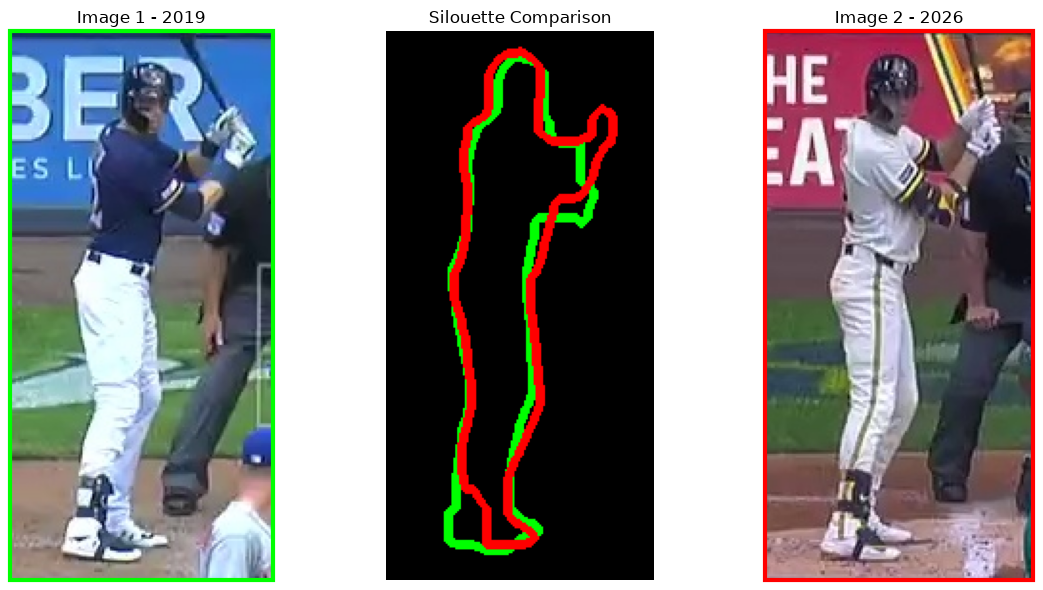

In [52]:
# read image 1 and image 2
image1 = cv2.imread(SOURCE_IMAGE_PATH_1)
image2 = cv2.imread(SOURCE_IMAGE_PATH_2)

# Convert BGR → RGB
image1_rgb = cv2.cvtColor(image1, cv2.COLOR_BGR2RGB)
image2_rgb = cv2.cvtColor(image2, cv2.COLOR_BGR2RGB)

# Create three plots side by side
fig, axes = plt.subplots(1, 3, figsize=(12, 6))

# Plot 1:
axes[0].imshow(image1_rgb)
axes[0].axis('off')
axes[0].set_title("Image 1 - 2019")

# green frame around image 1
h1, w1 = image1_rgb.shape[:2]

rect = Rectangle(
    (-0.5, -0.5),
    w1,
    h1,
    linewidth=3,
    edgecolor='lime',
    facecolor='none',
    clip_on=False
)

axes[0].add_patch(rect)


# PLot 2:
if silhouette1 is not None and silhouette2 is not None:

    # Size of the common canvas:
    h = max(silhouette1.shape[0], silhouette2.shape[0])
    w = max(silhouette1.shape[1], silhouette2.shape[1])

    combined = np.zeros((h, w, 3), dtype=np.uint8)

    # First silouette - green
    mask1 = np.any(silhouette1 > 0, axis=2)
    combined[:silhouette1.shape[0], :silhouette1.shape[1]][mask1] = (0, 255, 0)

    # Second silouette - red
    mask2 = np.any(silhouette2 > 0, axis=2)
    combined[:silhouette2.shape[0], :silhouette2.shape[1]][mask2] = (0, 0, 255)

    axes[1].imshow(cv2.cvtColor(combined, cv2.COLOR_BGR2RGB))
    axes[1].axis("off")
    axes[1].set_title("Silouette Comparison")
    

# PLot 3:
axes[2].imshow(image2_rgb)
axes[2].axis('off')
axes[2].set_title("Image 2 - 2026")

# red frame around image 2
h2, w2 = image2_rgb.shape[:2]

rect = Rectangle(
    (-0.5, -0.5),
    w2,
    h2,
    linewidth=3,
    edgecolor='red',
    facecolor='none',
    clip_on=False
)

axes[2].add_patch(rect)


# show:
plt.tight_layout()
plt.show()

Here, I aim to find images showing a very simimlar batting stance. Looking at the image from 2026, his front knee appears less bent, while his body weight appears to be shifted more towards his back leg which remains similarly bent. His hips also appear to be slightly more rotated towards the catcher. 

The largest difference is in the upper body position, which results in a straighter back and lower Back-Gluteal angle. His shoulders appear to be generally higher, reducing the distance between his shoulders and ears and making the upper body look more tight. His elbows also seems to be positioned closer to each other or to his body, possibly associated with the upper body tightness/elevated shoulders. 

Looking at the whole swing on video could possibly provide further insights into why his performance decreased while his angle improved. Also, more information about his surgery and postoperative recovery could also help to better understand the changes and their potentional relationship with his performance.

Contrary to previous findings, these results suggest, that there is no clear direct relationship between the Back-Gluteal angle and batting performance. However, changes in the Back-Gluteal angle may help identify changes in batting performance. 

Further analysis across multiple players could help determine whether the Back-Gluteal angle is associated with batting performance.